In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

DATASET_PATH = "/kaggle/input/datasets/paramaggarwal/fashion-product-images-dataset/fashion-dataset"

print("Dataset path:")
print(DATASET_PATH)

print("\nFiles available:")
print(os.listdir(DATASET_PATH))

Dataset path:
/kaggle/input/datasets/paramaggarwal/fashion-product-images-dataset/fashion-dataset

Files available:
['images.csv', 'images', 'styles.csv', 'styles', 'fashion-dataset']


In [2]:
styles_path = os.path.join(DATASET_PATH, "styles.csv")

print("Looking for:")
print(styles_path)

print("\nFile exists:", os.path.exists(styles_path))

Looking for:
/kaggle/input/datasets/paramaggarwal/fashion-product-images-dataset/fashion-dataset/styles.csv

File exists: True


In [3]:
df = pd.read_csv(
    styles_path,
    on_bad_lines="skip"
)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (44424, 10)

Columns:
['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName']


In [4]:
df.head()


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


In [5]:
print("Dataset shape:", df.shape)

print("\nAvailable columns:")
print(df.columns.tolist())

print("\nMaster Categories:")
print(df["masterCategory"].value_counts())

print("\nSub Categories:")
print(df["subCategory"].value_counts().head(30))

Dataset shape: (44424, 10)

Available columns:
['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName']

Master Categories:
masterCategory
Apparel           21397
Accessories       11274
Footwear           9219
Personal Care      2403
Free Items          105
Sporting Goods       25
Home                  1
Name: count, dtype: int64

Sub Categories:
subCategory
Topwear                     15402
Shoes                        7343
Bags                         3055
Bottomwear                   2694
Watches                      2542
Innerwear                    1808
Jewellery                    1079
Eyewear                      1073
Fragrance                    1011
Sandal                        963
Wallets                       933
Flip Flops                    913
Belts                         811
Socks                         698
Lips                          527
Dress                         478
Loungewear and Nightwea

In [6]:
SELECTED_CATEGORIES = [
    "Topwear",
    "Shoes",
    "Bags",
    "Bottomwear",
    "Dress",
    "Sandal"
]

MAX_IMAGES_PER_CATEGORY = 300

subset_df = (
    df[df["subCategory"].isin(SELECTED_CATEGORIES)]
    .groupby("subCategory", group_keys=False)
    .apply(
        lambda x: x.sample(
            n=min(len(x), MAX_IMAGES_PER_CATEGORY),
            random_state=42
        )
    )
    .reset_index(drop=True)
)

print("Selected categories:")
print(subset_df["subCategory"].value_counts())

print("\nTotal selected products:", len(subset_df))

Selected categories:
subCategory
Bags          300
Bottomwear    300
Dress         300
Sandal        300
Shoes         300
Topwear       300
Name: count, dtype: int64

Total selected products: 1800


/tmp/ipykernel_16/1258793929.py:15: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


In [7]:
print("Dataset directory:")
print(DATASET_PATH)

print("\nContents:")
print(os.listdir(DATASET_PATH))

Dataset directory:
/kaggle/input/datasets/paramaggarwal/fashion-product-images-dataset/fashion-dataset

Contents:
['images.csv', 'images', 'styles.csv', 'styles', 'fashion-dataset']


In [8]:
IMAGE_DIR = os.path.join(DATASET_PATH, "images")

# Create image path for every selected product
subset_df["image_path"] = subset_df["id"].apply(
    lambda x: os.path.join(IMAGE_DIR, f"{x}.jpg")
)

# Check whether each image exists
subset_df["image_exists"] = subset_df["image_path"].apply(os.path.exists)

print("Total selected products:", len(subset_df))
print("Images found:", subset_df["image_exists"].sum())
print("Images missing:", (~subset_df["image_exists"]).sum())

Total selected products: 1800
Images found: 1800
Images missing: 0


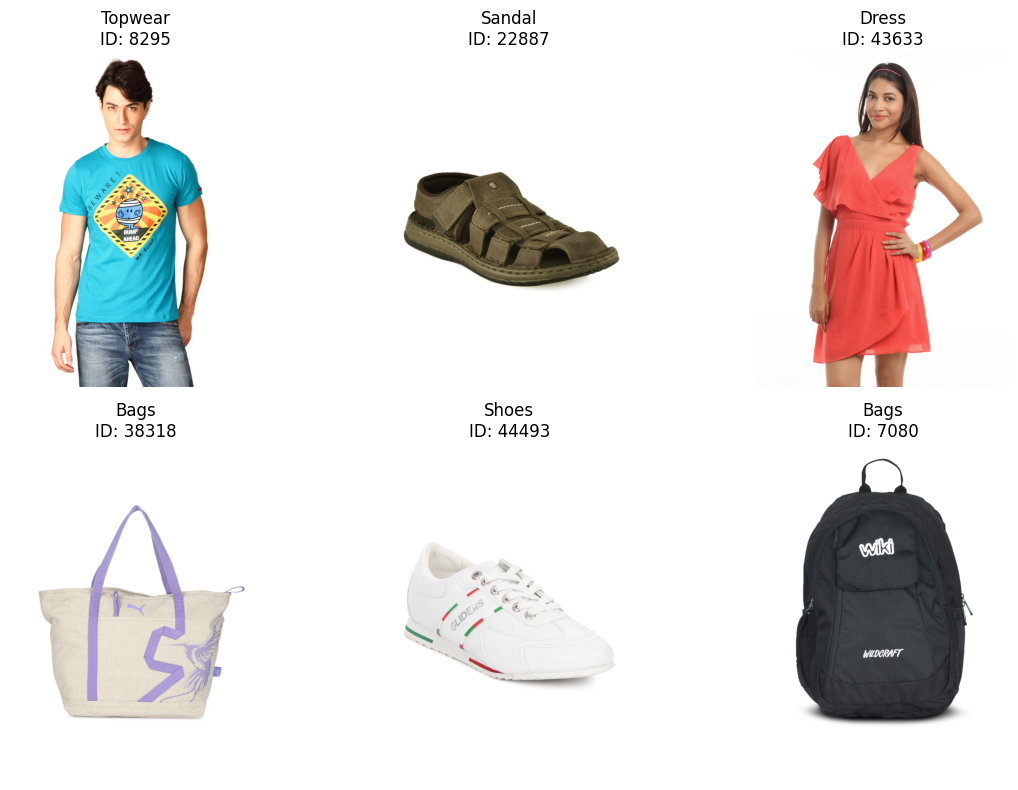

In [9]:
sample_products = subset_df.sample(6, random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (_, row) in zip(axes.flat, sample_products.iterrows()):
    image = Image.open(row["image_path"])

    ax.imshow(image)
    ax.set_title(
        f"{row['subCategory']}\nID: {row['id']}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

# First split: 70% train, 30% temporary
train_df, temp_df = train_test_split(
    subset_df,
    test_size=0.30,
    stratify=subset_df["subCategory"],
    random_state=42
)

# Second split: temporary into 15% validation and 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["subCategory"],
    random_state=42
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

Train: 1260
Validation: 270
Test: 270
Total: 1800


In [11]:
print("TRAIN DISTRIBUTION")
print(train_df["subCategory"].value_counts())

print("\nVALIDATION DISTRIBUTION")
print(val_df["subCategory"].value_counts())

print("\nTEST DISTRIBUTION")
print(test_df["subCategory"].value_counts())

TRAIN DISTRIBUTION
subCategory
Topwear       210
Dress         210
Bags          210
Bottomwear    210
Sandal        210
Shoes         210
Name: count, dtype: int64

VALIDATION DISTRIBUTION
subCategory
Topwear       45
Shoes         45
Dress         45
Bottomwear    45
Sandal        45
Bags          45
Name: count, dtype: int64

TEST DISTRIBUTION
subCategory
Dress         45
Bottomwear    45
Sandal        45
Topwear       45
Shoes         45
Bags          45
Name: count, dtype: int64


In [12]:
import os

ARTIFACT_DIR = "/kaggle/working/fashion_artifacts"

os.makedirs(ARTIFACT_DIR, exist_ok=True)

print("Artifact directory created:")
print(ARTIFACT_DIR)

Artifact directory created:
/kaggle/working/fashion_artifacts


In [13]:
train_df.to_csv(
    os.path.join(ARTIFACT_DIR, "train.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(ARTIFACT_DIR, "validation.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(ARTIFACT_DIR, "test.csv"),
    index=False
)

subset_df.to_csv(
    os.path.join(ARTIFACT_DIR, "subset_metadata.csv"),
    index=False
)

print("Saved files:")
print(os.listdir(ARTIFACT_DIR))

Saved files:
['train.csv', 'subset_metadata.csv', 'validation.csv', 'test.csv']


In [14]:
categories = sorted(subset_df["subCategory"].unique())

category_to_index = {
    category: index
    for index, category in enumerate(categories)
}

index_to_category = {
    index: category
    for category, index in category_to_index.items()
}

print("Category mapping:")
print(category_to_index)

Category mapping:
{'Bags': 0, 'Bottomwear': 1, 'Dress': 2, 'Sandal': 3, 'Shoes': 4, 'Topwear': 5}


In [15]:
import json

with open(
    os.path.join(ARTIFACT_DIR, "category_mapping.json"),
    "w"
) as f:
    json.dump(category_to_index, f, indent=4)

print("Category mapping saved.")

Category mapping saved.


In [16]:
print("=" * 50)
print("DATASET PREPARATION COMPLETE")
print("=" * 50)

print(f"Total images      : {len(subset_df)}")
print(f"Training images   : {len(train_df)}")
print(f"Validation images : {len(val_df)}")
print(f"Test images       : {len(test_df)}")
print(f"Categories        : {len(categories)}")

print("\nCategories:")
for category in categories:
    print(f"  - {category}")

print("\nArtifacts:")
for file in os.listdir(ARTIFACT_DIR):
    print(f"  ✓ {file}")

DATASET PREPARATION COMPLETE
Total images      : 1800
Training images   : 1260
Validation images : 270
Test images       : 270
Categories        : 6

Categories:
  - Bags
  - Bottomwear
  - Dress
  - Sandal
  - Shoes
  - Topwear

Artifacts:
  ✓ train.csv
  ✓ subset_metadata.csv
  ✓ validation.csv
  ✓ test.csv
  ✓ category_mapping.json


In [17]:
import os

print("Files ready for reuse:")
for root, dirs, files in os.walk("/kaggle/working/fashion_artifacts"):
    for file in files:
        print(os.path.join(root, file))

Files ready for reuse:
/kaggle/working/fashion_artifacts/train.csv
/kaggle/working/fashion_artifacts/subset_metadata.csv
/kaggle/working/fashion_artifacts/validation.csv
/kaggle/working/fashion_artifacts/test.csv
/kaggle/working/fashion_artifacts/category_mapping.json
